In [2]:
from radio_utilities import *
import json
import urllib.request
import pandas as pd
import time
import io
from zoneinfo import ZoneInfo
from astropy.time import Time

# Observations 31/07/2026 Rainy Weekend

In [3]:
with fits.open('../data/20260731/20260731_RT1.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT1 = astro_table.to_pandas()
    
x_RT1 = RT1['JD']
y_RT1 = RT1['LEFT_POL'].values

with fits.open('../data/20260731/20260731_RT2.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT2 = astro_table.to_pandas()
    
x_RT2 = RT2['JD']
y_RT2 = RT2['LEFT_POL'].values

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


In [4]:
def print_time_peak(time,flux,timezone="HKT"):
    '''Give the time in Julian date and the flux in any units and 
    you will get back the exact time of the peak. 
    You can choose the format to be timezone="UTC","HKT", "JD" '''
    # Find Julian Date of the peak
    jd_value = time[np.argmax(flux)]
    # Parse the Julian Date into an Astropy Time object (in UTC)
    t_utc = Time(jd_value, format="jd", scale="utc")
    # Convert to a Python datetime object with Hong Kong Time zone
    t_hk = t_utc.to_datetime(timezone=ZoneInfo("Asia/Hong_Kong"))
    if timezone=="UTC":
        print("UTC Time:      ", t_utc.iso)
        return t_utc.iso
    elif timezone=="HKT":
        print("Hong Kong Time:", t_hk.strftime("%Y-%m-%d %H:%M:%S %Z"))
        return t_hk.strftime("%Y-%m-%d %H:%M:%S %Z")
    elif timezone=="JD":
        print("Julian Time:   ",jd_value)
        return jd_value
    else:
        print("Choose a timezone between UTC, HKT or JD.")
        return np.nan

In [5]:
time_peak_rt1 = print_time_peak(x_RT1,y_RT1,timezone="HKT")
time_peak_rt2 = print_time_peak(x_RT2,y_RT2,timezone="HKT")
print("")

Hong Kong Time: 2026-08-01 13:57:56 HKT
Hong Kong Time: 2026-08-01 13:57:57 HKT



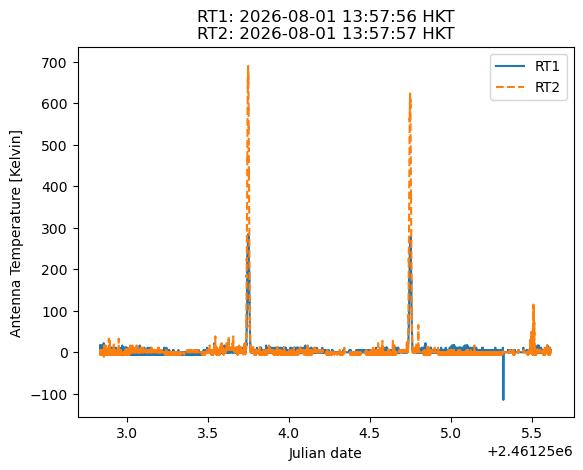

In [6]:
K_adu_to_kelvin = 5.46793637591984

plt.plot(x_RT1,K_adu_to_kelvin*(y_RT1-np.median(y_RT1)),label='RT1')
plt.plot(x_RT2,K_adu_to_kelvin*(y_RT2-np.median(y_RT2)),label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
#plt.savefig('./20260731/calibrated_fitsun2807.png')
plt.legend()
plt.show()

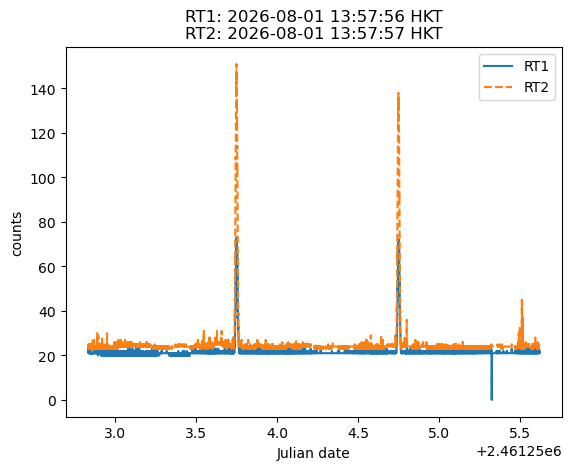

In [7]:
plt.plot(x_RT1,y_RT1,label='RT1')
plt.plot(x_RT2,y_RT2,label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('counts')
#plt.title('31/07/2026')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
plt.legend()
#plt.savefig('./20260731/uncalibrated.png')
plt.show()

# Observation 07/08/2026 Sunny Weekend

In [8]:
with fits.open('../data/20260807/20260807_RT1.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT1 = astro_table.to_pandas()
    
x_RT1 = RT1['JD']
y_RT1 = RT1['RIGHT_POL'].values

with fits.open('../data/20260807/20260807_RT2.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT2 = astro_table.to_pandas()
    
x_RT2 = RT2['JD']
y_RT2 = RT2['RIGHT_POL'].values

In [9]:
time_peak_rt1 = print_time_peak(x_RT1,y_RT1,timezone="HKT")
time_peak_rt2 = print_time_peak(x_RT2,y_RT2,timezone="HKT")
print("")

Hong Kong Time: 2026-08-07 16:29:42 HKT
Hong Kong Time: 2026-08-07 16:23:05 HKT



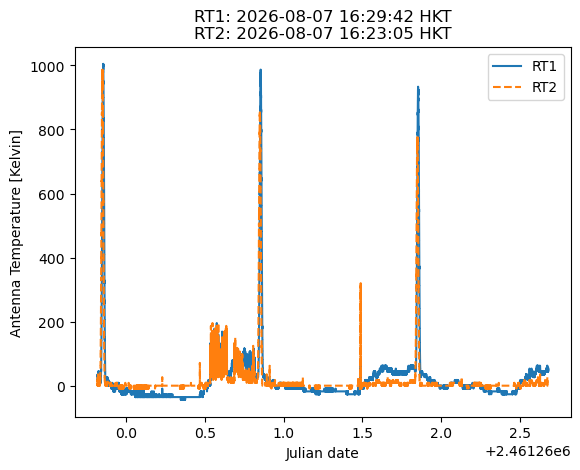

In [10]:
K_adu_to_kelvin = 8.891556495038369

plt.plot(x_RT1,K_adu_to_kelvin*(y_RT1-np.median(y_RT1)),label='RT1')
plt.plot(x_RT2,K_adu_to_kelvin*(y_RT2-np.median(y_RT2)),label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
#plt.savefig('./20260731/calibrated_fitsun2807.png')
plt.legend()
plt.show()

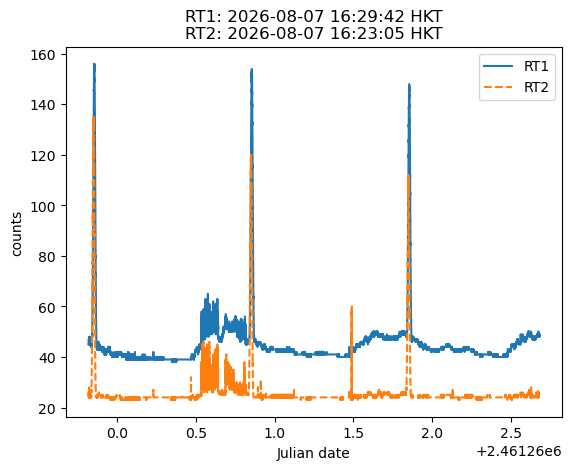

In [11]:
plt.plot(x_RT1,y_RT1,label='RT1')
plt.plot(x_RT2,y_RT2,label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('counts')
#plt.title('31/07/2026')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
plt.legend()
#plt.savefig('./20260731/uncalibrated.png')
plt.show()

# Cross correlation

In [59]:
import numpy as np
from scipy.signal import correlate

# --- ASSUMED INPUT DATA ---
# x_rt1, y_rt1: Julian Dates (x) and Counts (y) for RT1
# x_rt2, y_rt2: Julian Dates (x) and Counts (y) for RT2


def calculate_time_lag(x_rt1, y_rt1, x_rt2, y_rt2):
    """Calculates time lag between RT1 and RT2 given Julian Dates (x) and Counts (y)."""
    # 1. Convert sample step from Julian Days to Seconds
    # (1 Julian Day = 86,400 seconds)
    dt_days = np.median(np.diff(x_rt1))
    dt_seconds = dt_days * 86400.0

    print(f"Sampling interval: {dt_seconds:.3f} seconds per sample")

    # 2. Normalize signal counts (Subtract mean and divide by standard deviation)
    # This removes DC power offset and normalizes variance between the two dishes
    y1_norm = (y_rt1 - np.mean(y_rt1)) / np.std(y_rt1)
    y2_norm = (y_rt2 - np.mean(y_rt2)) / np.std(y_rt2)

    # 3. Compute cross-correlation
    corr = correlate(y1_norm, y2_norm, mode="full")

    # 4. Generate lag index array
    # Positive lag index means RT2 lags behind RT1
    lags = np.arange(-len(y1_norm) + 1, len(y1_norm))

    # 5. Find peak correlation location
    max_corr_idx = np.argmax(corr)
    peak_lag_samples = lags[max_corr_idx]

    # 6. Convert sample lag to seconds and minutes
    lag_seconds = peak_lag_samples * dt_seconds
    lag_minutes = lag_seconds / 60.0

    print(f"\n--- Cross-Correlation Results ---")
    print(f"Sample Lag: {peak_lag_samples} samples")
    print(f"Time Lag:   {lag_seconds:.2f} seconds ({lag_minutes:.2f} minutes)")

    if lag_seconds > 0:
        print("Result: RT2 events occur AFTER RT1 events.")
    elif lag_seconds < 0:
        print("Result: RT1 events occur AFTER RT2 events.")
    else:
        print("Result: Signals are perfectly synchronized.")

    return {
        "lags_seconds": lags * dt_seconds,
        "correlation": corr,
        "lag_seconds": lag_seconds,
        "lag_minutes": lag_minutes,
    }


# Example execution:
# results = calculate_time_lag(x_rt1, y_rt1, x_rt2, y_rt2)

In [60]:
#lags_seconds,correlation,lag_seconds,lag_minutes
results = calculate_time_lag(x_RT1,y_RT1,x_RT2,y_RT2)

Sampling interval: 1.060 seconds per sample

--- Cross-Correlation Results ---
Sample Lag: -11712 samples
Time Lag:   -12414.51 seconds (-206.91 minutes)
Result: RT1 events occur AFTER RT2 events.


ValueError: x and y must have same first dimension, but have shapes (430445,) and (417612,)

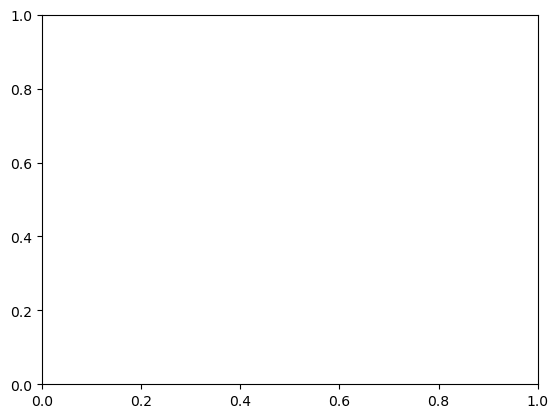

In [61]:
plt.plot(results['lags_seconds'],results['correlation'])
plt.show()

Common grid created: 233366 samples at 1.060 sec/sample

--- Cross-Correlation Results ---
Time Lag: 402.79 seconds (6.71 minutes)


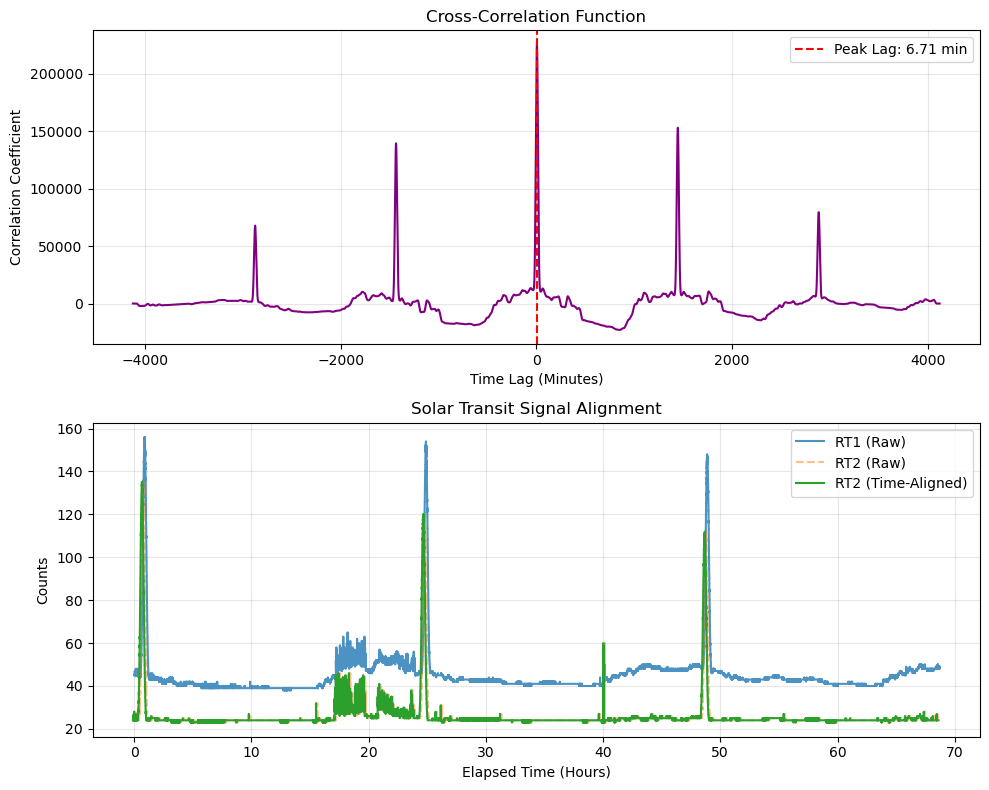

In [62]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import correlate


def align_and_correlate(x_RT1, y_RT1, x_RT2, y_RT2):
    """Handles different array lengths, interpolates onto a common grid,

    and computes the cross-correlation lag between RT1 and RT2.
    """
    # Convert inputs to NumPy arrays (fixes pandas Series [-1] KeyError)
    x_RT1 = np.asarray(x_RT1)
    y_RT1 = np.asarray(y_RT1)
    x_RT2 = np.asarray(x_RT2)
    y_RT2 = np.asarray(y_RT2)

    # 1. Define a common uniform Julian Date grid based on overlapping time span
    start_time = max(x_RT1[0], x_RT2[0])
    end_time = min(x_RT1[-1], x_RT2[-1])

    # Calculate average sample rate in seconds
    dt_days = min(np.median(np.diff(x_RT1)), np.median(np.diff(x_RT2)))
    dt_seconds = dt_days * 86400.0

    # Create common time grid
    common_x = np.arange(start_time, end_time, dt_days)

    # 2. Interpolate both signals onto the exact same time grid
    y1_interp = np.interp(common_x, x_RT1, y_RT1)
    y2_interp = np.interp(common_x, x_RT2, y_RT2)

    print(
        f"Common grid created: {len(common_x)} samples at {dt_seconds:.3f} sec/sample"
    )

    # 3. Normalize signals
    y1_norm = (y1_interp - np.mean(y1_interp)) / np.std(y1_interp)
    y2_norm = (y2_interp - np.mean(y2_interp)) / np.std(y2_interp)

    # 4. Compute cross-correlation
    corr = correlate(y1_norm, y2_norm, mode="full")
    lags = np.arange(-len(y1_norm) + 1, len(y1_norm))

    # 5. Find peak lag
    max_corr_idx = np.argmax(corr)
    peak_lag_samples = lags[max_corr_idx]

    lag_seconds = peak_lag_samples * dt_seconds
    lag_minutes = lag_seconds / 60.0

    print(f"\n--- Cross-Correlation Results ---")
    print(f"Time Lag: {lag_seconds:.2f} seconds ({lag_minutes:.2f} minutes)")

    return {
        "lags_seconds": lags * dt_seconds,
        "correlation": corr,
        "lag_seconds": lag_seconds,
        "lag_minutes": lag_minutes,
        "common_x": common_x,
    }


# --- EXECUTION AND PLOTTING ---

# Ensure execution inputs are also arrays for plotting calculations
x1_arr = np.asarray(x_RT1)
y1_arr = np.asarray(y_RT1)
x2_arr = np.asarray(x_RT2)
y2_arr = np.asarray(y_RT2)

# 1. Run alignment and cross-correlation
results = align_and_correlate(x1_arr, y1_arr, x2_arr, y2_arr)

# 2. Convert time arrays to elapsed hours relative to start of observation
t1_hours = (x1_arr - x1_arr[0]) * 24.0
t2_hours = (x2_arr - x1_arr[0]) * 24.0

# Aligned RT2 time array using measured lag
lag_days = results["lag_seconds"] / 86400.0
x_RT2_aligned = x2_arr - lag_days
t2_aligned_hours = (x_RT2_aligned - x1_arr[0]) * 24.0

# 3. Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Panel 1: Cross-Correlation Function
ax1.plot(
    results["lags_seconds"] / 60.0,
    results["correlation"],
    color="purple",
    lw=1.5,
)
ax1.axvline(
    results["lag_minutes"],
    color="red",
    linestyle="--",
    label=f"Peak Lag: {results['lag_minutes']:.2f} min",
)
ax1.set_title("Cross-Correlation Function")
ax1.set_xlabel("Time Lag (Minutes)")
ax1.set_ylabel("Correlation Coefficient")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Panel 2: Signal Alignment Plot
ax2.plot(t1_hours, y1_arr, label="RT1 (Raw)", color="tab:blue", alpha=0.8)
ax2.plot(
    t2_hours,
    y2_arr,
    label="RT2 (Raw)",
    color="tab:orange",
    alpha=0.5,
    linestyle="--",
)
ax2.plot(
    t2_aligned_hours,
    y2_arr,
    label="RT2 (Time-Aligned)",
    color="tab:green",
    lw=1.5,
)
ax2.set_title("Solar Transit Signal Alignment")
ax2.set_xlabel("Elapsed Time (Hours)")
ax2.set_ylabel("Counts")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

--- DAILY INDIVIDUAL LAG MEASUREMENTS ---
Friday (Day 1) Time Lag: 6.68 minutes
Saturday (Day 2) Time Lag: 6.75 minutes
Sunday (Day 3) Time Lag: 6.70 minutes


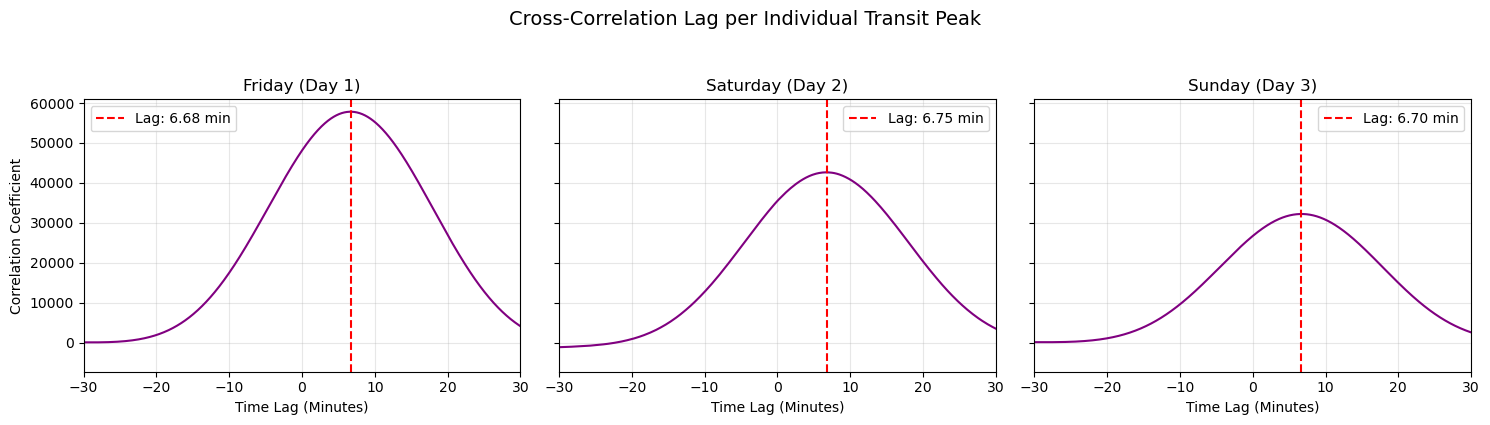

In [63]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import correlate


def measure_single_transit_lag(x_RT1, y_RT1, x_RT2, y_RT2):
    """Interpolates a single transit onto a common grid and calculates time lag."""
    x_RT1, y_RT1 = np.asarray(x_RT1), np.asarray(y_RT1)
    x_RT2, y_RT2 = np.asarray(x_RT2), np.asarray(y_RT2)

    start_time = max(x_RT1[0], x_RT2[0])
    end_time = min(x_RT1[-1], x_RT2[-1])

    dt_days = min(np.median(np.diff(x_RT1)), np.median(np.diff(x_RT2)))
    dt_seconds = dt_days * 86400.0
    common_x = np.arange(start_time, end_time, dt_days)

    y1_interp = np.interp(common_x, x_RT1, y_RT1)
    y2_interp = np.interp(common_x, x_RT2, y_RT2)

    y1_norm = (y1_interp - np.mean(y1_interp)) / np.std(y1_interp)
    y2_norm = (y2_interp - np.mean(y2_interp)) / np.std(y2_interp)

    corr = correlate(y1_norm, y2_norm, mode="full")
    lags = np.arange(-len(y1_norm) + 1, len(y1_norm))

    max_corr_idx = np.argmax(corr)
    peak_lag_samples = lags[max_corr_idx]

    lag_seconds = peak_lag_samples * dt_seconds
    lag_minutes = lag_seconds / 60.0

    return lags * dt_seconds / 60.0, corr, lag_minutes


# --- SLICE DATA BY DAY AND COMPARE LAGS ---

# Convert Julian Dates to elapsed days from start of observation
start_jd = min(np.min(x_RT1), np.min(x_RT2))
days_RT1 = np.asarray(x_RT1) - start_jd
days_RT2 = np.asarray(x_RT2) - start_jd

# Define 4-hour window masks around each transit (~Day 0, Day 1, Day 2)
# Adjust window boundaries if your transits occur at slightly different times
transit_windows = [
    ("Friday (Day 1)", 0.0, 0.35),  # First peak
    ("Saturday (Day 2)", 0.8, 1.35),  # Second peak
    ("Sunday (Day 3)", 1.8, 2.35),  # Third peak
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

print("--- DAILY INDIVIDUAL LAG MEASUREMENTS ---")

for i, (day_name, t_start, t_end) in enumerate(transit_windows):
    # Mask for RT1 and RT2
    m1 = (days_RT1 >= t_start) & (days_RT1 <= t_end)
    m2 = (days_RT2 >= t_start) & (days_RT2 <= t_end)

    # Check if data exists in this window
    if np.sum(m1) > 10 and np.sum(m2) > 10:
        lags_min, corr, lag_min = measure_single_transit_lag(
            np.asarray(x_RT1)[m1],
            np.asarray(y_RT1)[m1],
            np.asarray(x_RT2)[m2],
            np.asarray(y_RT2)[m2],
        )

        print(f"{day_name} Time Lag: {lag_min:.2f} minutes")

        # Plot correlation curve for this day
        axes[i].plot(lags_min, corr, color="purple", lw=1.5)
        axes[i].axvline(
            lag_min,
            color="red",
            linestyle="--",
            label=f"Lag: {lag_min:.2f} min",
        )
        axes[i].set_xlim(-30, 30)  # Zoom in on +-30 minutes around zero
        axes[i].set_title(f"{day_name}")
        axes[i].set_xlabel("Time Lag (Minutes)")
        axes[i].grid(True, alpha=0.3)
        axes[i].legend()
    else:
        axes[i].set_title(f"{day_name} (No Data)")

axes[0].set_ylabel("Correlation Coefficient")
plt.suptitle(
    "Cross-Correlation Lag per Individual Transit Peak", fontsize=14, y=1.05
)
plt.tight_layout()
plt.show()